# M and A, workshop 2 — Keys, duplicates and the values that lie

Last week you got three files to load correctly. They are still unusable: the same customer
appears twice under two spellings, a gender column speaks six languages, and one email address
belongs to 499 different people.

Today:

1. **Concat or merge?** — the question everyone answers wrong first.
2. **Normalise before you compare**, or your duplicates stay invisible.
3. **Decode a coded column from evidence**, instead of guessing.
4. **Deduplicate honestly**, including the key that is not a key.

In [ ]:
# ABOUTME: M and A workshop 2 - merge keys, normalisation and deduplication.
# ABOUTME: Includes decoding a 0/1 column from overlapping records and the placeholder-email trap.
import csv
import io
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 20)

In [ ]:
from pathlib import Path

WORK = Path("sample_files")      # three little files, written next to this notebook
WORK.mkdir(exist_ok=True)

# --- Shop A: a normal CSV export. Quoted names, a placeholder email, a country typed as a number.
(WORK / "shop_a.csv").write_text(
    "Gender,FirstName,LastName,UserName,Email,Age,City,Country\n"
    "Female,latesha,Barton,latesha,forgottoask@woodinc,85,INDIANAPOLIS,United State Of America\n"
    'Female,Yolando,"Jast",yolando,yolando_jast@yahoo.com,53,Columbus,12\n'
    "Male,BRANDON,Hyatt,brandon,brandon.hyatt@gmail.com,41,new_york,U.S.A.\n"
    "M,chase,OBERBRUNNER,chase,CHASE.OBERBRUNNER@HOTMAIL.COM,29,Austin,US\n"
    "0,Erwin,Kuhic,erwin,forgottoask@woodinc,66,Phoenix,USA\n"
    "1,Tawanda,Lind,tawanda,tawanda.lind@yahoo.com,37,Seattle,U.S.\n"
)

# --- Shop B: no header, ';' separated, columns in another order, and no country column at all.
(WORK / "shop_b.csv").write_text(
    '"51";austin;1;"lorette" kutch;Kutch.lorette@gmail.com\n'
    '"84";san diego;Female;CLORINDA WIZA;clorinda.wiza@gmail.com\n'
    '"97";Columbus;Male;"\\"Joesph\\"" "littel";LITTEL.JOESPH@GMAIL.COM\n'
    '"23";New_York;0;carlo Stokes;carlo.stokes@hotmail.com\n'
    '"45";Chicago;M;KASEY "prosacco";kasey_prosacco@gmail.com\n'
    '"61";Dallas;F;brandon hyatt;brandon.hyatt@gmail.com\n'
)

# --- Shop C: header names comma separated, rows TAB separated, every value carrying its type.
(WORK / "shop_c.csv").write_text(
    "Gender,Name,Email,Age,City,Country\n"
    'string_Male\tstring_kendall DACH\tstring_DACH.KENDALL@HOTMAIL.COM\t"integer_26"\tstring_Dallas\tstring_United_State_Of_America\n'
    'string_Male\tstring_jonathon "schneider"\tstring_Jonathon.schneider@gmail.com\t"integer_91"\tstring_INDIANAPOLIS\tstring_Us\n'
    'boolean_1\tstring_JAROD konopelski\tstring_KONOPELSKI_JAROD@HOTMAIL.COM\t"integer_38"\tstring_Chicago\tstring_1\n'
    'character_M\tstring_marta Bergstrom\tstring_marta.bergstrom@yahoo.com\t"integer_52"\tstring_Phoenix\tstring_u.s.a.\n'
    'boolean_0\tstring_SHERYL hamill\tstring_sheryl.hamill@gmail.com\t"integer_19"\tstring_Austin\tstring_US\n'
    'string_Female\tstring_lorette kutch\tstring_Kutch.lorette@gmail.com\t"integer_51"\tstring_Austin\tstring_U.S.\n'
)

print("wrote", ", ".join(sorted(p.name for p in WORK.iterdir())))

wrote shop_a.csv, shop_b.csv, shop_c.csv


In [ ]:
# The three loaders from workshop 1, so this notebook stands alone.
shop_a = pd.read_csv(WORK / "shop_a.csv")
shop_b = pd.read_csv(WORK / "shop_b.csv", sep=";", header=None,
                     names=["age", "city", "gender", "name", "email"])
_header, _body = (WORK / "shop_c.csv").read_text().split("\n", 1)
shop_c = pd.read_csv(io.StringIO(_body), sep="\t", header=None,
                     names=_header.strip().split(","), quoting=csv.QUOTE_NONE)
print(shop_a.shape, shop_b.shape, shop_c.shape)

(6, 8) (6, 5) (6, 6)


## 1. Concat, not merge

`pd.merge` joins tables **side by side**: same entities, different attributes. Customers and their
orders. That is not our situation.

Here all three files hold *the same kind of row* — a customer with a name, an email, a city. We are
stacking them **on top of each other** and then collapsing the rows that describe the same person.
That is `pd.concat`, followed by deduplication.

**Rule of thumb:** merge when you are adding columns; concat when you are adding rows. If you
cannot say which columns the join would add, you do not want a join.

## 2. Normalise before you compare

Two rows describe the same customer only if you can *see* that they do. Right now you cannot.

In [ ]:
pd.DataFrame({
    "gender":  [sorted(shop_a.Gender.astype(str).unique()), sorted(shop_b.gender.astype(str).unique()),
                sorted(shop_c.Gender.astype(str).unique())],
    "country": [sorted(shop_a.Country.astype(str).unique()), ["(no column)"],
                sorted(shop_c.Country.astype(str).unique())],
}, index=["shop_a", "shop_b", "shop_c"])

,gender,country
shop_a,"[0, 1, Female, M, Male]","[12, U.S., U.S.A., US, USA, United State Of Am..."
shop_b,"[0, 1, F, Female, M, Male]",[(no column)]
shop_c,"[boolean_0, boolean_1, character_M, string_Fem...","[string_1, string_U.S., string_US, string_Unit..."


Six ways to say a gender, eight to say the United States, and `shop_c` wraps every value in its
own type name. Before any comparison, every column needs **one** representation.

Start with the easy ones: strip the type prefixes, the stray quotes, and the case.

In [ ]:
def strip_types(s):
    """shop_c wrote the type into the value: string_Male, "integer_26", boolean_1, character_M."""
    return (s.astype(str)
             .str.replace(r'^"|"$', "", regex=True)
             .str.replace(r"^(string|integer|character|boolean|float)_", "", regex=True))

def clean_text(s):
    """Stray quotes and backslashes survive from three generations of bad exports."""
    return (s.astype(str)
             .str.replace(r'[\\"]', "", regex=True)
             .str.strip()
             .replace({"": None, "nan": None}))

print("before:", shop_c.Gender.tolist())
print("after :", strip_types(shop_c.Gender).tolist())
print()
print("before:", shop_b.name.tolist())
print("after :", clean_text(shop_b.name).tolist())

before: ['string_Male', 'string_Male', 'boolean_1', 'character_M', 'boolean_0', 'string_Female']
after : ['Male', 'Male', '1', 'M', '0', 'Female']

before: ['lorette kutch', 'CLORINDA WIZA', '\\Joesph\\"" "littel"', 'carlo Stokes', 'KASEY "prosacco"', 'brandon hyatt']
after : ['lorette kutch', 'CLORINDA WIZA', 'Joesph littel', 'carlo Stokes', 'KASEY prosacco', 'brandon hyatt']


### Exercise 1 — normalise the country

`US`, `USA`, `U.S.A.`, `U.S.`, `Us`, `u.s.a.`, `United State Of America`, `United-State-Of-America`
are one country. `12` and `1` are not countries at all.

Write `normalise_country`: every real spelling becomes `"United States of America"`, and anything
unrecognisable becomes `None` (do **not** invent a country for it).

Hint: lowercase, delete everything that is not a letter, then compare against a small set.

In [ ]:
def normalise_country(s):
    """Map every spelling of the USA onto one string; unrecognised values become None."""
    v = clean_text(s)
    key = v.str.lower().str.replace(r"[^a-z]", "", regex=True)
    usa = {"us", "usa", "unitedstateofamerica", "unitedstatesofamerica", "unitedstates", "america"}
    return key.map(lambda k: "United States of America" if k in usa else None)

test_values = pd.Series(["US", "USA", "U.S.A.", "united-state-of-america", "Us", "12", "1", None])
normalise_country(test_values).tolist()

['United States of America',
 'United States of America',
 'United States of America',
 'United States of America',
 'United States of America',
 None,
 None,
 None]

In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

_out = normalise_country(test_values)
check("all six spellings collapse to one", lambda: _out[:5].nunique() == 1)
check("that one value is the full name", lambda: _out.iloc[0] == "United States of America")
check("12 and 1 become None", lambda: _out.iloc[5] is None and _out.iloc[6] is None)

  all six spellings collapse to one: PASS
  that one value is the full name: PASS
  12 and 1 become None: PASS


True

**The punchline:** `12` is not a country, and the honest output is "missing". Filling it with
"United States of America" because every other row says so is inventing data — and the person who
reads your table in six months has no way to tell which values you made up.

## 3. Decode the gender column from evidence

`shop_a` and `shop_b` both use `0` and `1` for some rows. Does `1` mean male or female?

You could guess. Or you could notice that **some customers appear in two files at once** — explicit
in one, coded in the other. Those records decide it.

In [ ]:
# Build one small frame of (email, gender, source) over the three files, with emails comparable.
def gender_rows(df, email_col, gender_col, source):
    return pd.DataFrame({"email": clean_text(strip_types(df[email_col])).str.lower(),
                         "gender": clean_text(strip_types(df[gender_col])),
                         "source": source})

rows = pd.concat([gender_rows(shop_a, "Email", "Gender", "shop_a"),
                  gender_rows(shop_b, "email", "gender", "shop_b"),
                  gender_rows(shop_c, "Email", "Gender", "shop_c")], ignore_index=True)
rows[rows.duplicated("email", keep=False)].sort_values("email")

,email,gender,source
2,brandon.hyatt@gmail.com,Male,shop_a
11,brandon.hyatt@gmail.com,F,shop_b
0,forgottoask@woodinc,Female,shop_a
4,forgottoask@woodinc,0,shop_a
6,kutch.lorette@gmail.com,1,shop_b
17,kutch.lorette@gmail.com,Female,shop_c


Read the table. Two customers appear twice:

- **lorette kutch** — `1` in shop_b, `Female` in shop_c.
- **brandon hyatt** — `Male` in shop_a, `F` in shop_b.

The first pair is evidence: `1` and `Female` describe the same person. The second pair is a
**conflict** — two systems disagree about one customer, which no amount of cleaning can resolve.

**Rule of thumb:** one clean record pair beats any amount of intuition. In the full exports there
are exactly three such pairs, and all three agree that `0` is male.

### Exercise 2 — normalise the gender

Using that evidence: `0` is male, `1` is female. Map `Male/M/0` to `"Male"`, `Female/F/1` to
`"Female"`, and anything else to `None`.

In [ ]:
def normalise_gender(s):
    """Six encodings down to two values: Male, Female. 0 = Male, 1 = Female (see the evidence above)."""
    v = clean_text(strip_types(s)).str.lower()
    return v.map({"male": "Male", "m": "Male", "0": "Male",
                  "female": "Female", "f": "Female", "1": "Female"})

g_values = pd.Series(["Male", "M", "0", "Female", "F", "1", "boolean_1", "???"])
normalise_gender(g_values).tolist()

['Male', 'Male', 'Male', 'Female', 'Female', 'Female', 'Female', nan]

In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

_g = normalise_gender(g_values)
check("the three male spellings agree", lambda: set(_g[:3]) == {"Male"})
check("the three female spellings agree", lambda: set(_g[3:6]) == {"Female"})
check("boolean_1 survives the type prefix", lambda: _g.iloc[6] == "Female")
check("nonsense becomes None", lambda: pd.isna(_g.iloc[7]))

  the three male spellings agree: PASS
  the three female spellings agree: PASS
  boolean_1 survives the type prefix: PASS
  nonsense becomes None: PASS


True

## 4. The key that is not a key

Email is the only identifier the three systems share, so it is the natural key for deduplication.
Look at it first.

In [ ]:
emails = clean_text(strip_types(pd.concat([shop_a.Email, shop_b.email, shop_c.Email]))).str.lower()
print(emails.value_counts().head(3).to_string())

forgottoask@woodinc        2
brandon.hyatt@gmail.com    2
kutch.lorette@gmail.com    2


`forgottoask@woodinc` — twice here, **499 times in the real export**. It is not an address, it is a
shrug: whoever typed the form never asked for the email. It also has no dot after the `@`, so it is
not even a valid address.

Deduplicate on it and you merge 499 unrelated customers into one.

**Rule of thumb:** before a column becomes your key, check its most frequent values. A key with a
popular value is not a key.

### Exercise 3 — a valid-email filter

Write `valid_email`: lowercase the address, and return `None` for anything that is not shaped like
`something@something.tld`. Those rows keep their other data — they just cannot be matched on email.

In [ ]:
def valid_email(s):
    """Lowercase real addresses; anything not shaped like a@b.tld becomes None."""
    v = clean_text(strip_types(s)).str.lower()
    return v.where(v.str.match(r"^[^@\s]+@[^@\s]+\.[a-z]{2,}$", na=False))

e_values = pd.Series(["A.B@Gmail.com", "forgottoask@woodinc", "nope", None, "x@y.co"])
valid_email(e_values).tolist()

['a.b@gmail.com', nan, nan, nan, 'x@y.co']

In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

_e = valid_email(e_values)
check("real addresses are lowercased", lambda: _e.iloc[0] == "a.b@gmail.com")
check("the placeholder is rejected", lambda: pd.isna(_e.iloc[1]))
check("junk is rejected", lambda: pd.isna(_e.iloc[2]) and pd.isna(_e.iloc[3]))
check("a short TLD still passes", lambda: _e.iloc[4] == "x@y.co")

  real addresses are lowercased: PASS
  the placeholder is rejected: PASS
  junk is rejected: PASS
  a short TLD still passes: PASS


True

### Exercise 4 — count the duplicates, three ways

Now measure what normalisation bought you. Stack the three files' emails and count distinct
customers under three policies:

1. **raw** — emails exactly as stored
2. **normalised** — lowercased and trimmed
3. **validated** — normalised, with invalid addresses excluded from the count

The difference between 1 and 2 is the duplicates you could not see. The difference between 2 and 3
is the customers you would have wrongly merged.

In [ ]:
raw_emails = pd.concat([shop_a.Email, shop_b.email, shop_c.Email], ignore_index=True)

n_rows = len(raw_emails)
n_raw_distinct = raw_emails.nunique()
normalised = clean_text(strip_types(raw_emails)).str.lower()
n_normalised_distinct = normalised.nunique()
n_valid_distinct = valid_email(raw_emails).nunique()

print(f"rows                  : {n_rows}")
print(f"distinct raw          : {n_raw_distinct}")
print(f"distinct normalised   : {n_normalised_distinct}")
print(f"distinct valid        : {n_valid_distinct}")
print()
print(f"hidden duplicates found by normalising : {n_raw_distinct - n_normalised_distinct}")
print(f"rows with no usable key                : {n_rows - valid_email(raw_emails).notna().sum()}")

rows                  : 18
distinct raw          : 16
distinct normalised   : 15
distinct valid        : 14

hidden duplicates found by normalising : 1
rows with no usable key                : 2


In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

check("counts are filled in", lambda: all(isinstance(x, (int,)) or hasattr(x, "item")
                                          for x in [n_raw_distinct, n_normalised_distinct, n_valid_distinct]))
check("normalising finds hidden duplicates", lambda: n_normalised_distinct < n_raw_distinct)
check("the placeholder is out of the valid count", lambda: n_valid_distinct < n_normalised_distinct)

  counts are filled in: PASS
  normalising finds hidden duplicates: PASS
  the placeholder is out of the valid count: PASS


True

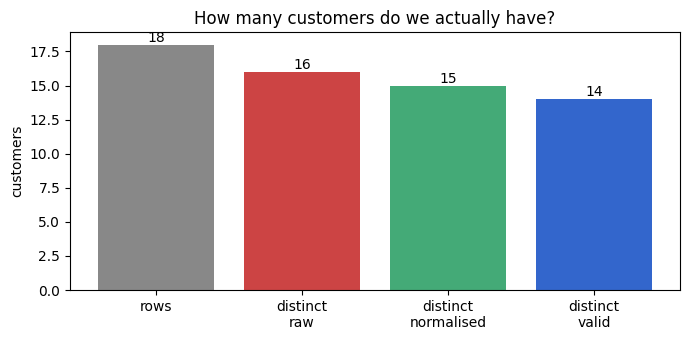

In [ ]:
counts = {"rows": n_rows, "distinct\nraw": n_raw_distinct,
          "distinct\nnormalised": n_normalised_distinct, "distinct\nvalid": n_valid_distinct}

if any(v is None for v in counts.values()):
    print("Fill in the four counts in the exercise above, then run this cell to see them side by side.")
else:
    fig, ax = plt.subplots(figsize=(7, 3.5))
    bars = ax.bar(list(counts), list(counts.values()), color=["#888", "#c44", "#4a7", "#36c"])
    ax.bar_label(bars)
    ax.set_ylabel("customers"); ax.set_title("How many customers do we actually have?")
    plt.tight_layout()

Four different answers to "how many customers did we buy?", from the same three files. Only the
last one is defensible, and you can only reach it by cleaning **before** counting.

## 5. Resolving a conflict

`brandon.hyatt@gmail.com` is `Male` in shop_a and `F` in shop_b. One record, two answers. Your
options, in order of honesty:

1. **Keep the record from the more trustworthy source**, and write down which one that is and why.
2. **Keep the first occurrence** (`drop_duplicates(keep="first")`) — fine, as long as you are
   honest that it is arbitrary.
3. **Keep the most complete record** — the one with the fewest missing fields. Usually the best
   default when you have no reason to trust one system over another.
4. Average them. There is no average of `Male` and `F`. Do not.

Whatever you choose: it is a decision, it goes in the migration notes, and it is the kind of thing
your reviewer will ask about.

## What to take away

1. **Concat adds rows, merge adds columns.** Three customer lists is a concat.
2. **Normalise, then compare.** Duplicates that differ in case or punctuation are invisible until
   you remove case and punctuation.
3. **Decode coded columns from overlapping records**, not from intuition. Three honest pairs beat
   a confident guess.
4. **Check the frequent values of your key before trusting it.** `forgottoask@woodinc` would have
   merged 499 strangers into one customer.
5. **Missing is a legitimate value.** Inventing a country to avoid a `NaN` makes your table look
   complete and be wrong.

### Take it home
On the full exports: how many distinct valid emails do the three files hold together, and how many
rows have no usable key at all? Bring both numbers — they are the first two lines of your
migration report.